## NAÏVE BAYES ON A REVIEW CLASSIFICATION DATASET

### TASK 1: Load & Explore the Dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
# Display all columns
pd.set_option('display.max_columns', None)

In [6]:
df=pd.read_csv(r"D:\MACHINE LEARNING\output.csv")

In [11]:
#Display First 10 Rows
df.head(10)

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,1
4,The selection on the menu was great and so were the prices.,1
5,Now I am getting angry and I want my damn pho.,0
6,Honeslty it didn't taste THAT fresh.),0
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,0
8,The fries were great too.,1
9,A great touch.,1


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0    Review  1000 non-null   object
 1   Liked    1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB


In [14]:
df.columns

Index([' Review', 'Liked'], dtype='object')

In [17]:
#Number of samples per class
df['Liked'].value_counts()

Liked
1    500
0    500
Name: count, dtype: int64

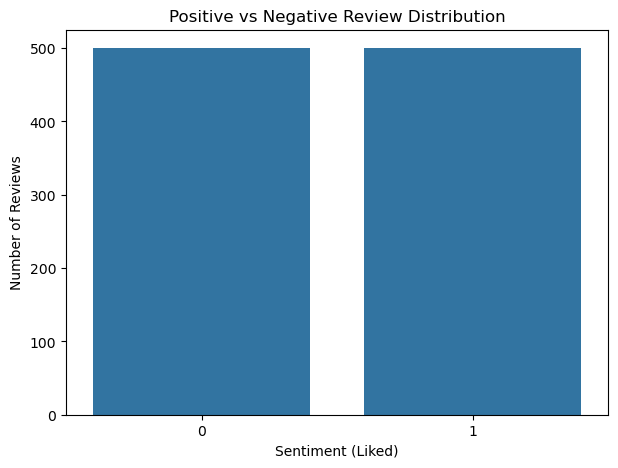

In [20]:
# Visualize Class Distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Liked')

plt.title("Positive vs Negative Review Distribution")
plt.xlabel("Sentiment (Liked)")
plt.ylabel("Number of Reviews")

plt.show()

Explanation:

- value_counts() counts the number of records in each class.

- countplot() displays the class distribution visually.

In [22]:
#Check Missing Values
df.isnull().sum()

Review    0
Liked     0
dtype: int64

In [25]:
#Missing Value Percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage

Review    0.0
Liked     0.0
dtype: float64

In [27]:
#Calculate Review text Length
df['Review_length'] = df['Review'].fillna('').astype(str).apply(len)
# Display first 10 review lengths
df[['Review', 'Review_length']].head(10)


,Review,Review_length
0,Wow... Loved this place.,24
1,Crust is not good.,18
2,Not tasty and the texture was just nasty.,41
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,87
4,The selection on the menu was great and so were the prices.,59
5,Now I am getting angry and I want my damn pho.,46
6,Honeslty it didn't taste THAT fresh.),37
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,111
8,The fries were great too.,25
9,A great touch.,14


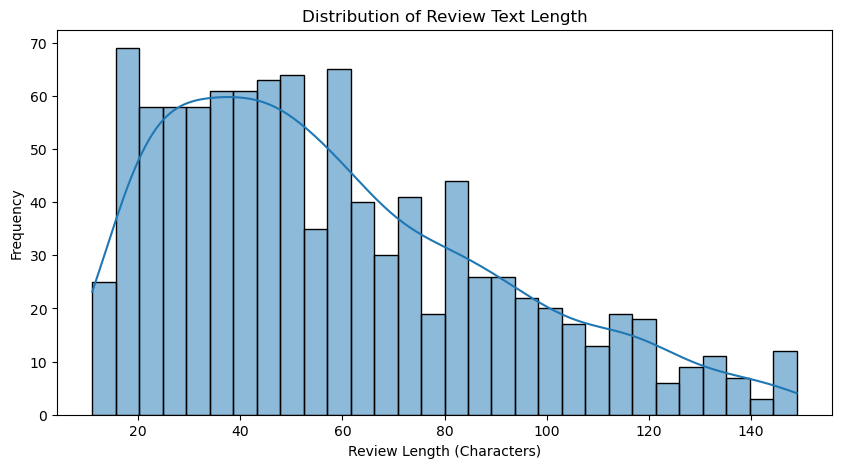

In [29]:
#Review Length Distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Review_length',
    bins=30,
    kde=True
)

plt.title("Distribution of Review Text Length")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Frequency")

plt.show()

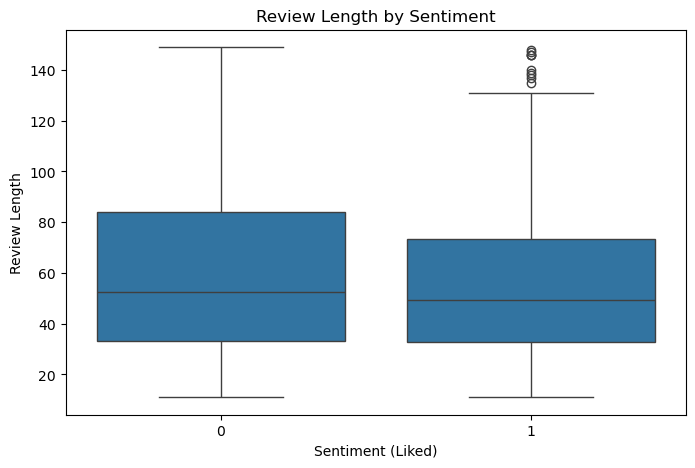

In [30]:
#Compare Review Length by Sentiment
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Liked',
    y='Review_length'
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment (Liked)")
plt.ylabel("Review Length")

plt.show()


### TASK 2: Clean & Preprocess the Text

In [31]:
import pandas as pd
import numpy as np
import re
import string

In [32]:
import nltk

In [34]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [35]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [36]:
#Convert Text to Lowercase
df['Review_clean'] = df['Review'].fillna('').astype(str).str.lower()

# Display original and lowercase reviews
df[['Review', 'Review_clean']].head(10)


,Review,Review_clean
0,Wow... Loved this place.,wow... loved this place.
1,Crust is not good.,crust is not good.
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty.
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stopped by during the late may bank holiday off rick steve recommendation and loved it.
4,The selection on the menu was great and so were the prices.,the selection on the menu was great and so were the prices.
5,Now I am getting angry and I want my damn pho.,now i am getting angry and i want my damn pho.
6,Honeslty it didn't taste THAT fresh.),honeslty it didn't taste that fresh.)
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,the potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.
8,The fries were great too.,the fries were great too.
9,A great touch.,a great touch.


In [37]:
#Remove Punctuation
def remove_punctuation(text):
    return text.translate(str.maketrans('', '', string.punctuation))

df['Review_clean'] = df['Review_clean'].apply(remove_punctuation)

# Display results
df[['Review', 'Review_clean']].head(10)


,Review,Review_clean
0,Wow... Loved this place.,wow loved this place
1,Crust is not good.,crust is not good
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stopped by during the late may bank holiday off rick steve recommendation and loved it
4,The selection on the menu was great and so were the prices.,the selection on the menu was great and so were the prices
5,Now I am getting angry and I want my damn pho.,now i am getting angry and i want my damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty it didnt taste that fresh
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,the potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer
8,The fries were great too.,the fries were great too
9,A great touch.,a great touch


In [38]:
#Remove Numbers
def remove_numbers(text):
    return re.sub(r'\d+', '', text)

df['Review_clean'] = df['Review_clean'].apply(remove_numbers)

# Display results
df[['Review', 'Review_clean']].head(10)


,Review,Review_clean
0,Wow... Loved this place.,wow loved this place
1,Crust is not good.,crust is not good
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stopped by during the late may bank holiday off rick steve recommendation and loved it
4,The selection on the menu was great and so were the prices.,the selection on the menu was great and so were the prices
5,Now I am getting angry and I want my damn pho.,now i am getting angry and i want my damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty it didnt taste that fresh
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,the potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer
8,The fries were great too.,the fries were great too
9,A great touch.,a great touch


In [39]:
#Remove Extra Spaces
def remove_extra_spaces(text):
    return re.sub(r'\s+', ' ', text).strip()

df['Review_clean'] = df['Review_clean'].apply(remove_extra_spaces)

# Display results
df[['Review', 'Review_clean']].head(10)


,Review,Review_clean
0,Wow... Loved this place.,wow loved this place
1,Crust is not good.,crust is not good
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stopped by during the late may bank holiday off rick steve recommendation and loved it
4,The selection on the menu was great and so were the prices.,the selection on the menu was great and so were the prices
5,Now I am getting angry and I want my damn pho.,now i am getting angry and i want my damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty it didnt taste that fresh
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,the potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer
8,The fries were great too.,the fries were great too
9,A great touch.,a great touch


In [41]:
#Remove Stopwords
stop_words = set(stopwords.words('english'))

# Keep negation words because they are important for sentiment
# classification (e.g. "not good" and "good" mean different things).
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

def remove_stopwords(text):
    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(filtered_words)

df['Review_clean'] = df['Review_clean'].apply(remove_stopwords)

# Display results
df[['Review', 'Review_clean']].head(10)


,Review,Review_clean
0,Wow... Loved this place.,wow loved place
1,Crust is not good.,crust not good
2,Not tasty and the texture was just nasty.,not tasty texture nasty
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stopped late may bank holiday rick steve recommendation loved
4,The selection on the menu was great and so were the prices.,selection menu great prices
5,Now I am getting angry and I want my damn pho.,getting angry want damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty didnt taste fresh
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,potatoes like rubber could tell made ahead time kept warmer
8,The fries were great too.,fries great
9,A great touch.,great touch


In [42]:
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger_eng.zip.


True

In [44]:
#Lemmatization
lemmatizer = WordNetLemmatizer()

# Convert NLTK POS tags into WordNet POS tags

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'  # Adjective
    elif tag.startswith('V'):
        return 'v'  # Verb
    elif tag.startswith('N'):
        return 'n'  # Noun
    elif tag.startswith('R'):
        return 'r'  # Adverb
    else:
        return 'n'

def lemmatize_text(text):
    words = nltk.word_tokenize(text)

    pos_tags = nltk.pos_tag(words)

    lemmatized_words = []

    for word, tag in pos_tags:
        pos = get_wordnet_pos(tag)

        lemmatized_word = lemmatizer.lemmatize(word, pos)

        lemmatized_words.append(lemmatized_word)

    return ' '.join(lemmatized_words)

df['Review_clean'] = df['Review_clean'].apply(lemmatize_text)

# Display results
df[['Review', 'Review_clean']].head(10)


,Review,Review_clean
0,Wow... Loved this place.,wow love place
1,Crust is not good.,crust not good
2,Not tasty and the texture was just nasty.,not tasty texture nasty
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stop late may bank holiday rick steve recommendation love
4,The selection on the menu was great and so were the prices.,selection menu great price
5,Now I am getting angry and I want my damn pho.,get angry want damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty didnt taste fresh
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,potato like rubber could tell make ahead time keep warmer
8,The fries were great too.,fry great
9,A great touch.,great touch


In [49]:
# Optional: Remove Emojis
import emoji

def remove_emojis(text):
    return emoji.replace_emoji(text, replace='')

df['Review_clean'] = df['Review_clean'].apply(remove_emojis)
print("Emojis removed successfully!")

Emojis removed successfully!


In [50]:

# Step 11: Compare Original and Cleaned Reviews
print("Original Reviews vs Cleaned Reviews")

df[['Review', 'Review_clean', 'Liked']].head(10)


Original Reviews vs Cleaned Reviews


,Review,Review_clean,Liked
0,Wow... Loved this place.,wow love place,1
1,Crust is not good.,crust not good,0
2,Not tasty and the texture was just nasty.,not tasty texture nasty,0
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stop late may bank holiday rick steve recommendation love,1
4,The selection on the menu was great and so were the prices.,selection menu great price,1
5,Now I am getting angry and I want my damn pho.,get angry want damn pho,0
6,Honeslty it didn't taste THAT fresh.),honeslty didnt taste fresh,0
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,potato like rubber could tell make ahead time keep warmer,0
8,The fries were great too.,fry great,1
9,A great touch.,great touch,1


### TASK 3: Convert Text to Numerical Features

In [54]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [59]:
#Prepare Input Text

X_text = df['Review_clean'].fillna('').astype(str)

# Prepare Target Variable

y = df['Liked']

print("Input text prepared successfully!")

print(X_text.head())


Input text prepared successfully!
0                                               wow love place
1                                               crust not good
2                                      not tasty texture nasty
3    stop late may bank holiday rick steve recommendation love
4                                   selection menu great price
Name: Review_clean, dtype: object


In [60]:
#Bag of Words using CountVectorizer

count_vectorizer = CountVectorizer()

X_bow = count_vectorizer.fit_transform(X_text)

print("Bag of Words conversion completed!")

print("\nShape of BOW Matrix:")
print(X_bow.shape)

Bag of Words conversion completed!

Shape of BOW Matrix:
(1000, 1704)


In [61]:
#Display Vocabulary

vocabulary = count_vectorizer.get_feature_names_out()

print("First 20 Vocabulary Words:")

print(vocabulary[:20])

print("\nTotal Unique Words:")

print(len(vocabulary))


First 20 Vocabulary Words:
['absolute' 'absolutely' 'absolutley' 'accident' 'accommodation'
 'accomodate' 'accordingly' 'accountant' 'ache' 'acknowledge' 'across'
 'actual' 'actually' 'add' 'affordable' 'afternoon' 'ago' 'ahead'
 'airline' 'airport']

Total Unique Words:
1704


In [62]:
#Display BOW Numerical Matrix

bow_df = pd.DataFrame(
    X_bow.toarray(),
    columns=vocabulary
)

print("Bag of Words Matrix:")

bow_df.head(10)


Bag of Words Matrix:


absolute  absolutely  absolutley  accident  accommodation  accomodate  \
0         0           0           0         0              0           0   
1         0           0           0         0              0           0   
2         0           0           0         0              0           0   
3         0           0           0         0              0           0   
4         0           0           0         0              0           0   
5         0           0           0         0              0           0   
6         0           0           0         0              0           0   
7         0           0           0         0              0           0   
8         0           0           0         0              0           0   
9         0           0           0         0              0           0   

   accordingly  accountant  ache  acknowledge  across  actual  actually  add  \
0            0           0     0            0       0       0         0    0   
1            0           0     0            0       0       0         0    0   
2            0           0     0            0       0       0         0    0   
3            0           0     0            0       0       0         0    0   
4            0           0     0            0       0       0         0    0   
5            0           0     0            0       0       0         0    0   
6            0           0     0            0       0       0         0    0   
7            0           0     0            0       0       0         0    0   
8            0           0     0            0       0       0         0    0   
9            0           0     0            0       0       0         0    0   

   affordable  afternoon  ago  ahead  airline  airport  ala  albondigas  \
0           0          0    0      0        0        0    0           0   
1           0          0    0      0        0        0    0           0   
2           0          0    0      0        0        0    0           0   
3           0          0    0      0        0        0    0           0   
4           0          0    0      0        0        0    0           0   
5           0          0    0      0        0        0    0           0   
6           0          0    0      0        0        0    0           0   
7           0          0    0      1        0        0    0           0   
8           0          0    0      0        0        0    0           0   
9           0          0    0      0        0        0    0           0   

   allergy  almonds  almost  alone  also  although  always  amaze  amazing  \
0        0        0       0      0     0         0       0      0        0   
1        0        0       0      0     0         0       0      0        0   
2        0        0       0      0     0         0       0      0        0   
3        0        0       0      0     0         0       0      0        0   
4        0        0       0      0     0         0       0      0        0   
5        0        0       0      0     0         0       0      0        0   
6        0        0       0      0     0         0       0      0        0   
7        0        0       0      0     0         0       0      0        0   
8        0        0       0      0     0         0       0      0        0   
9        0        0       0      0     0         0       0      0        0   

   amazingrge  ambiance  ambience  amount  ample  andddd  angry  another  \
0           0         0         0       0      0       0      0        0   
1           0         0         0       0      0       0      0        0   
2           0         0         0       0      0       0      0        0   
3           0         0         0       0      0       0      0        0   
4           0         0         0       0      0       0      0        0   
5           0         0         0       0      0       0      1        0   
6           0         0         0       0      0       0      0     

In [63]:
#TF-IDF Vectorization

tfidf_vectorizer = TfidfVectorizer()

X_tfidf = tfidf_vectorizer.fit_transform(X_text)

print("TF-IDF conversion completed!")

print("\nShape of TF-IDF Matrix:")

print(X_tfidf.shape)


TF-IDF conversion completed!

Shape of TF-IDF Matrix:
(1000, 1704)


In [64]:
#Display TF-IDF Vocabulary

tfidf_vocabulary = tfidf_vectorizer.get_feature_names_out()

print("First 20 TF-IDF Words:")

print(tfidf_vocabulary[:20])

print("\nTotal Vocabulary Size:")

print(len(tfidf_vocabulary))


First 20 TF-IDF Words:
['absolute' 'absolutely' 'absolutley' 'accident' 'accommodation'
 'accomodate' 'accordingly' 'accountant' 'ache' 'acknowledge' 'across'
 'actual' 'actually' 'add' 'affordable' 'afternoon' 'ago' 'ahead'
 'airline' 'airport']

Total Vocabulary Size:
1704


In [65]:
#Display TF-IDF Matrix

tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    columns=tfidf_vocabulary
)

print("TF-IDF Numerical Matrix:")

tfidf_df.head(10)


TF-IDF Numerical Matrix:


absolute  absolutely  absolutley  accident  accommodation  accomodate  \
0       0.0         0.0         0.0       0.0            0.0         0.0   
1       0.0         0.0         0.0       0.0            0.0         0.0   
2       0.0         0.0         0.0       0.0            0.0         0.0   
3       0.0         0.0         0.0       0.0            0.0         0.0   
4       0.0         0.0         0.0       0.0            0.0         0.0   
5       0.0         0.0         0.0       0.0            0.0         0.0   
6       0.0         0.0         0.0       0.0            0.0         0.0   
7       0.0         0.0         0.0       0.0            0.0         0.0   
8       0.0         0.0         0.0       0.0            0.0         0.0   
9       0.0         0.0         0.0       0.0            0.0         0.0   

   accordingly  accountant  ache  acknowledge  across  actual  actually  add  \
0          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
1          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
2          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
3          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
4          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
5          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
6          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
7          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
8          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   
9          0.0         0.0   0.0          0.0     0.0     0.0       0.0  0.0   

   affordable  afternoon  ago     ahead  airline  airport  ala  albondigas  \
0         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   
1         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   
2         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   
3         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   
4         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   
5         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   
6         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   
7         0.0        0.0  0.0  0.391514      0.0      0.0  0.0         0.0   
8         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   
9         0.0        0.0  0.0  0.000000      0.0      0.0  0.0         0.0   

   allergy  almonds  almost  alone  also  although  always  amaze  amazing  \
0      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
1      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
2      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
3      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
4      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
5      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
6      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
7      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
8      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   
9      0.0      0.0     0.0    0.0   0.0       0.0     0.0    0.0      0.0   

   amazingrge  ambiance  ambience  amount  ample  andddd     angry  another  \
0         0.0       0.0       0.0     0.0    0.0     0.0  0.000000      0.0   
1         0.0       0.0       0.0     0.0    0.0     0.0  0.000000      0.0   
2         0.0       0.0       0.0     0.0    0.0     0.0  0.000000      0.0   
3         0.0       0.0       0.0     0.0    0.0     0.0  0.000000      0.0   
4         0.0       0.0       0.0     0.0    0.0     0.0  0.000000      0.0   
5         0.0       0.0       0.0     0.0    0.0     0.0  0.553591      0.0   
6         0.0 

In [66]:
#Compare Both Techniques

print("Bag of Words Shape:", X_bow.shape)

print("TF-IDF Shape:", X_tfidf.shape)

print("\nVocabulary Comparison:")

print("BOW Vocabulary:", len(vocabulary))

print("TF-IDF Vocabulary:", len(tfidf_vocabulary))


Bag of Words Shape: (1000, 1704)
TF-IDF Shape: (1000, 1704)

Vocabulary Comparison:
BOW Vocabulary: 1704
TF-IDF Vocabulary: 1704


### TASK 4: Split the Data

In [67]:
from sklearn.model_selection import train_test_split

In [68]:
X = df['Review_clean'].fillna('').astype(str)

# Target variable (sentiment)
y = df['Liked']

In [69]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data size:", len(X_train))
print("Testing data size:", len(X_test))

Training data size: 800
Testing data size: 200


In [70]:
print("Training set percentage:", len(X_train) / len(X) * 100)
print("Testing set percentage:", len(X_test) / len(X) * 100)

Training set percentage: 80.0
Testing set percentage: 20.0


### TASK 5: Train Naïve Bayes Models

In [71]:
from sklearn.feature_extraction.text import CountVectorizer

# Convert reviews into binary word features
binary_vectorizer = CountVectorizer(binary=True)

X_train_binary = binary_vectorizer.fit_transform(X_train)
X_test_binary = binary_vectorizer.transform(X_test)

print("Training matrix shape:", X_train_binary.shape)
print("Testing matrix shape:", X_test_binary.shape)

Training matrix shape: (800, 1486)
Testing matrix shape: (200, 1486)


In [73]:
from sklearn.naive_bayes import BernoulliNB

# Create the model
bernoulli_model = BernoulliNB()

# Train the model
bernoulli_model.fit(X_train_binary, y_train)

,alpha,1.0
,force_alpha,True
,binarize,0.0
,fit_prior,True
,class_prior,None


In [74]:
y_pred_bernoulli = bernoulli_model.predict(X_test_binary)

print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(y_pred_bernoulli[:10])

Actual values:
[1 0 0 0 1 1 1 1 0 0]
Predicted values:
[1 0 0 1 1 1 1 0 0 0]


### TASK 6: Evaluate Naïve Bayes Models

In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [81]:
# Calculate evaluation metrics
bernoulli_accuracy = accuracy_score(y_test, y_pred_bernoulli)

bernoulli_precision = precision_score(
    y_test, y_pred_bernoulli, zero_division=0
)

bernoulli_recall = recall_score(
    y_test, y_pred_bernoulli, zero_division=0
)

bernoulli_f1 = f1_score(
    y_test, y_pred_bernoulli, zero_division=0
)

print("BERNOULLI NAIVE BAYES EVALUATION")
print("--------------------------------")
print("Accuracy :", round(bernoulli_accuracy, 4))
print("Precision:", round(bernoulli_precision, 4))
print("Recall   :", round(bernoulli_recall, 4))
print("F1 Score :", round(bernoulli_f1, 4))

BERNOULLI NAIVE BAYES EVALUATION
--------------------------------
Accuracy : 0.82
Precision: 0.8019
Recall   : 0.85
F1 Score : 0.8252


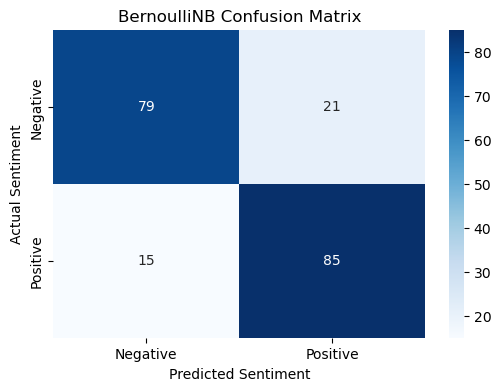

In [82]:
cm = confusion_matrix(y_test, y_pred_bernoulli)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("BernoulliNB Confusion Matrix")

plt.show()

In [83]:
print("BernoulliNB Classification Report")
print("---------------------------------")

print(classification_report(
    y_test,
    y_pred_bernoulli,
    target_names=['Negative', 'Positive'],
    zero_division=0
))

BernoulliNB Classification Report
---------------------------------
              precision    recall  f1-score   support

    Negative       0.84      0.79      0.81       100
    Positive       0.80      0.85      0.83       100

    accuracy                           0.82       200
   macro avg       0.82      0.82      0.82       200
weighted avg       0.82      0.82      0.82       200



In [84]:
def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print("\n", model_name, "EVALUATION")
    print("=" * 40)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=['Negative', 'Positive'],
        zero_division=0
    ))

    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }

In [85]:
bernoulli_results = evaluate_model(
    "BernoulliNB",
    y_test,
    y_pred_bernoulli
)


 BernoulliNB EVALUATION
Accuracy : 0.82
Precision: 0.8019
Recall   : 0.85
F1 Score : 0.8252

Confusion Matrix:
[[79 21]
 [15 85]]

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.79      0.81       100
    Positive       0.80      0.85      0.83       100

    accuracy                           0.82       200
   macro avg       0.82      0.82      0.82       200
weighted avg       0.82      0.82      0.82       200



### TASK 7: Predict Sentiment of New Reviews
#### Part 1: Predict sentiment of new reviews in Jupyter Notebook

In [98]:
#Enter samplr reviews
new_reviews = [
    "The food was fantastic!",
    "Worst service ever."
]

In [99]:
new_reviews

['The food was fantastic!', 'Worst service ever.']

In [100]:
#Preprocess the new reviews
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

stop_words = set(stopwords.words('english'))

# Preserve important negation words
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('N'):
        return 'n'
    elif tag.startswith('R'):
        return 'r'
    return 'n'

def preprocess_review(text):
    text = str(text).lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    words = [word for word in text.split() if word not in stop_words]

    pos_tags = nltk.pos_tag(words)

    words = [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in pos_tags
    ]

    return ' '.join(words)

cleaned_reviews = [preprocess_review(review) for review in new_reviews]

print(cleaned_reviews)

['food fantastic', 'bad service ever']


In [101]:
#Convert review into binary features
new_reviews_vectorized = binary_vectorizer.transform(cleaned_reviews)
new_reviews_vectorized 

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 5 stored elements and shape (2, 1486)>

In [102]:
#Predict sentiment
predictions = bernoulli_model.predict(new_reviews_vectorized)

for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-----------------------------")

Review: The food was fantastic!
Predicted Sentiment: Positive
-----------------------------
Review: Worst service ever.
Predicted Sentiment: Negative
-----------------------------


#### Part 2: Prepare your model files for Streamlit

In [103]:
#Save thr trained odel and vectorizer
import joblib

# Save trained BernoulliNB model
joblib.dump(bernoulli_model, "bernoulli_model.pkl")

# Save fitted binary vectorizer
joblib.dump(binary_vectorizer, "binary_vectorizer.pkl")


['binary_vectorizer.pkl']

In [97]:
from IPython.display import FileLink

display(FileLink("bernoulli_model.pkl"))
display(FileLink("binary_vectorizer.pkl"))

C:\Users\user\bernoulli_model.pkl

C:\Users\user\binary_vectorizer.pkl